# Lab 01-07 · Applications of Integration

Companion to chapter [01-07](../../chapters/01-07-applications-of-integration.md). Handout: [README.md](README.md).

Run the cells in order. Cells marked **🔮 Predict** ask you to write a prediction *before* running.

In [1]:
import math, shutil, subprocess, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass

## Part 1 — An RMS calculator, and two kinds of meter

`measure(x)` returns the average, RMS, crest factor, and what an average-responding meter (calibrated for sines) would display.

In [2]:
def measure(x):
    avg = x.mean()
    rms = math.sqrt((x**2).mean())
    rect = np.abs(x).mean()
    meter = rect * math.pi / (2 * math.sqrt(2))
    return avg, rms, np.abs(x).max() / rms, meter

t = np.linspace(0, 1, 200000, endpoint=False)
waves = {
    "sine":            np.sin(2 * np.pi * t),
    "square":          np.sign(np.sin(2 * np.pi * t)),
    "triangle":        2 / np.pi * np.arcsin(np.sin(2 * np.pi * t)),
    "PWM 25% (0/1)":   np.where(t < 0.25, 1.0, 0.0),
    "rectifier pulse": np.where(np.abs(np.sin(2*np.pi*t)) > 0.9, np.sign(np.sin(2*np.pi*t)), 0.0),
}
print(f"{'wave':<16}{'avg':>8}{'RMS':>8}{'crest':>8}{'avg-resp meter':>16}{'error':>8}")
for name, x in waves.items():
    avg, rms, crest, meter = measure(x)
    print(f"{name:<16}{avg:8.3f}{rms:8.3f}{crest:8.3f}{meter:16.3f}{100*(meter/rms-1):7.1f}%")

wave                 avg     RMS   crest  avg-resp meter   error
sine               0.000   0.707   1.414           0.707   -0.0%
square             0.000   1.000   1.000           1.111   11.1%
triangle           0.000   0.577   1.732           0.555   -3.8%
PWM 25% (0/1)      0.250   0.500   2.000           0.278  -44.5%
rectifier pulse    0.000   0.536   1.866           0.319  -40.5%


The last row is a crude model of the current drawn by a rectifier with a capacitor filter: narrow pulses near the voltage peaks. Note how badly an average-responding meter under-reads it.

## Part 2 — Quantization noise and 6.02N + 1.76 dB

**🔮 Predict** the SNR of a 10-bit quantizer driven by a sine at *half* of full scale.

In [3]:
def quantize_snr(N, amplitude=1.0, n=200_000, seed=0):
    rng = np.random.default_rng(seed)
    phase = rng.uniform(0, 2 * np.pi)
    x = amplitude * np.sin(2 * np.pi * 0.0123457 * np.arange(n) + phase)   # full scale is ±1
    delta = 2 / 2**N
    xq = np.clip(np.round(x / delta) * delta, -1, 1 - delta)
    err = xq - x
    return 10 * math.log10((x**2).mean() / (err**2).mean()), err.std() / delta

for N in [8, 10, 12, 14]:
    snr, sig = quantize_snr(N, amplitude=1 - 2 / 2**N)
    print(f"N = {N:2d}: measured SNR {snr:6.2f} dB, ideal {6.02*N + 1.76:6.2f} dB, error std {sig:.4f} LSB (1/sqrt(12) = {1/math.sqrt(12):.4f})")
snr_half, _ = quantize_snr(10, amplitude=0.5)
print(f"10 bits at half scale: {snr_half:.2f} dB")

N =  8: measured SNR  49.89 dB, ideal  49.92 dB, error std 0.2875 LSB (1/sqrt(12) = 0.2887)
N = 10: measured SNR  61.96 dB, ideal  61.96 dB, error std 0.2883 LSB (1/sqrt(12) = 0.2887)
N = 12: measured SNR  74.06 dB, ideal  74.00 dB, error std 0.2869 LSB (1/sqrt(12) = 0.2887)
N = 14: measured SNR  86.06 dB, ideal  86.04 dB, error std 0.2883 LSB (1/sqrt(12) = 0.2887)
10 bits at half scale: 56.02 dB


## Part 3 — Reliability and yield as integrals

fraction surviving 720 h: simulated 0.8664, integral exp(-lam t) = 0.8659
fraction failing before the mean: 0.6328  (1 - 1/e = 0.6321)
within ±1%:   0.9546  (Gaussian integral 0.9545)
within ±0.5%: 0.6845  (Gaussian integral 0.6827)


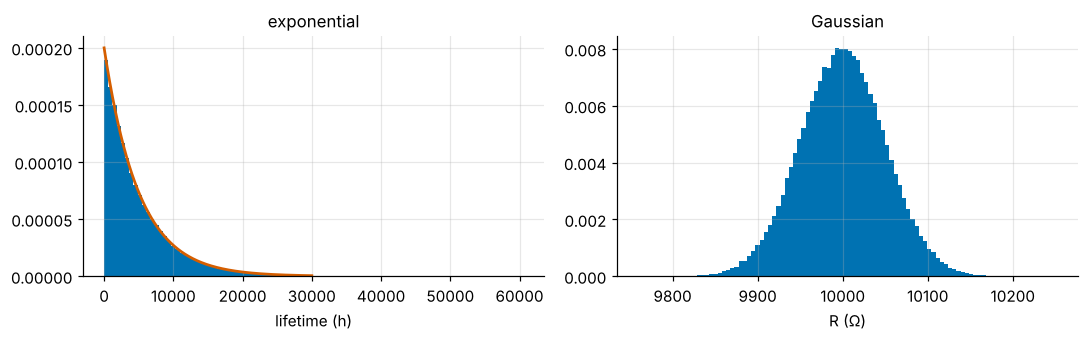

In [4]:
rng = np.random.default_rng(1)
lam = 1 / 5000.0                       # per hour: the server of Problem 01-07.10
life = rng.exponential(1 / lam, 200_000)
print(f"fraction surviving 720 h: simulated {np.mean(life > 720):.4f}, integral exp(-lam t) = {math.exp(-lam*720):.4f}")
print(f"fraction failing before the mean: {np.mean(life < 1/lam):.4f}  (1 - 1/e = {1 - math.exp(-1):.4f})")

R = rng.normal(10_000, 50, 200_000)
print(f"within ±1%:   {np.mean(abs(R - 1e4) <= 100):.4f}  (Gaussian integral 0.9545)")
print(f"within ±0.5%: {np.mean(abs(R - 1e4) <= 50):.4f}  (Gaussian integral 0.6827)")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(life, bins=100, density=True); tt = np.linspace(0, 30000, 300); ax[0].plot(tt, lam * np.exp(-lam * tt))
ax[0].set_xlabel("lifetime (h)"); ax[0].set_title("exponential")
ax[1].hist(R, bins=100, density=True); ax[1].set_xlabel("R (Ω)"); ax[1].set_title("Gaussian")
plt.tight_layout(); plt.show()

## Part 4 — ngspice measures RMS and average power

`rms_power.cir` is checked by `python tools/run_spice.py 01-07` from the repository root. The cell below runs it directly if ngspice is installed.

In [5]:
if shutil.which("ngspice"):
    out = subprocess.run(["ngspice", "-b", "rms_power.cir"], capture_output=True, text=True).stdout
    for l in out.splitlines():
        if "=" in l and l.split("=")[0].strip() in ("pwm_avg", "pwm_rms", "tri_rms", "p_avg", "i_rms"):
            print("   " + l.strip())
else:
    print("ngspice not found; see SETUP.md. Skipping.")

   pwm_avg             =  3.000428e+00 from=  1.000000e-03 to=  1.100000e-02
   pwm_rms             =   6.00043e+00 from=  1.00000e-03 to=  1.10000e-02
   tri_rms             =   5.77351e-01 from=  1.00000e-03 to=  1.10000e-02
   p_avg               =  7.361479e+02 from=  1.000000e-01 to=  2.000000e-01
   i_rms               =   7.07130e+00 from=  1.00000e-01 to=  2.00000e-01


## Your turn

1. In Part 1, build the current of a full-wave rectifier with a 10% conduction angle per half cycle. What is its crest factor?
2. In Part 2, add Gaussian noise of 0.5 LSB RMS before quantizing a 12-bit converter. Predict the new SNR and the resulting ENOB, then measure them.